# Assignment: Build and Test a Machine-Learned Interatomic Potential



### Instructions
1. Complete every cell marked `# TODO`. Do **not** change the names or signatures of the functions you are asked to write, because the check cells call them.
2. After each task, run the **check cell** that follows it. A check prints `PASSED` when your implementation is correct. Passing checks is necessary but not sufficient for full marks: plots, tables and written answers are graded too.
3. Only NumPy and Matplotlib are allowed. Do not import ASE, PyTorch, scikit-learn or any MLIP package.
4. Use the practice-session notebook and the class notes as references. Copying code from the practice notebook is allowed **only** where it is marked as provided here. Everything else must be written by you.
5. Submit the executed notebook (`.ipynb`) with all outputs visible.

### The problem
You will build a linear MLIP for an 8-atom cluster described by a reference potential that differs from the one in the practice session: a **Morse** pair potential plus a three-body term that favours **90°** bond angles. All quantities are in reduced units ($D_e=1$, $r_0=1$, $m=1$, $k_B=1$).


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def check(cond, msg=""):
    print("PASSED" if cond else f"FAILED  {msg}")

# ---- provided helpers (same as in the practice session) ----
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]          # D[i, j] = r_j - r_i
    return D, np.linalg.norm(D, axis=-1)

def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

rng = np.random.default_rng(2026)

---
## Task A. Morse potential: energy and analytic forces
$$
V(r)=D_e\Big[\big(1-e^{-a(r-r_0)}\big)^2-1\Big],\qquad E_{\rm Morse}=\sum_{i<j}V(r_{ij})
$$

with $D_e=1$, $a=3$, $r_0=1$.

**A1 (3 pts).** Show by hand (write it in the markdown cell below) that $V(r_0)=-D_e$ and that

$$
V'(r)=2aD_e\,e^{-a(r-r_0)}\big(1-e^{-a(r-r_0)}\big).
$$

**A2 (7 pts).** Implement `morse_energy(R)` and `morse_forces(R)`. The force must be **analytic** (use $\mathbf F_i=\sum_{j\ne i}V'(r_{ij})\,\mathbf d_{ij}/r_{ij}$ with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$). Do not call `numerical_forces` inside `morse_forces`.

### **A1. Your derivation:**

1. **Value of $V(r)$ at $r = r_0$:**
$$
V(r_0) = D_e \Big[ \big(1 - e^{-a(r_0-r_0)}\big)^2 - 1 \Big] = D_e \Big[ \big(1 - e^{0}\big)^2 - 1 \Big] = D_e \big[ 0^2 - 1 \big] = -D_e.
$$

2. **Derivative of $V(r)$:**
Using the chain rule with $u(r) = 1 - e^{-a(r-r_0)}$:
$$
\frac{d}{dr} \Big[ \big(1 - e^{-a(r-r_0)}\big)^2 \Big] = 2 \big(1 - e^{-a(r-r_0)}\big) \cdot \frac{d}{dr}\big(1 - e^{-a(r-r_0)}\big)
$$
Since $\frac{d}{dr}\big(1 - e^{-a(r-r_0)}\big) = a e^{-a(r-r_0)}$, we get:
$$
V'(r) = 2 a D_e e^{-a(r-r_0)} \big(1 - e^{-a(r-r_0)}\big).
$$

In [9]:
D_E, A_M, R0_M = 1.0, 3.0, 1.0

def morse_energy(R):
    # TODO: return the total Morse energy (sum over pairs i < j)
    _, r = pair_geometry(R)
    N = R.shape[0]
    # Extract upper triangle elements (i < j)
    iu = np.triu_indices(N, k=1)
    rij = r[iu]
    v_r = D_E * ((1.0 - np.exp(-A_M * (rij - R0_M)))**2 - 1.0)
    return np.sum(v_r)

def morse_forces(R):
    # TODO: return an (N, 3) array of analytic forces
    D, r = pair_geometry(R)
    N = R.shape[0]
    F = np.zeros_like(R)

    # Avoid division by zero on the diagonal
    r_eps = np.where(r == 0, np.inf, r)

    # Calculate analytical derivative V'(r)
    exp_term = np.exp(-A_M * (r_eps - R0_M))
    v_prime = 2.0 * A_M * D_E * exp_term * (1.0 - exp_term)

    # Force F_i = \sum_{j \neq i} V'(r_{ij}) * d_{ij} / r_{ij}
    # where d_{ij} = r_j - r_i
    # Note: D[i, j] is already (r_j - r_i)
    np.fill_diagonal(v_prime, 0.0)
    F = np.sum((v_prime / r_eps)[:, :, None] * D, axis=1)
    return F

In [10]:
# ---- check A ----
dimer = np.array([[0.0, 0, 0], [1.0, 0, 0]])
check(np.isclose(morse_energy(dimer), -1.0), "V(r0) should be -1")
dimer2 = np.array([[0.0, 0, 0], [1.3, 0, 0]])
y = np.exp(-3 * 0.3)
check(np.isclose(morse_energy(dimer2), (1 - y)**2 - 1), "dimer energy at r = 1.3")
Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + rng.normal(scale=0.08, size=(8, 3))
err = np.abs(morse_forces(Rt) - numerical_forces(morse_energy, Rt)).max()
check(err < 1e-6, f"analytic vs numerical force difference = {err:.2e}")
check(np.allclose(morse_forces(Rt).sum(0), 0, atol=1e-10), "forces must sum to zero (Newton's third law)")

PASSED
PASSED
PASSED
PASSED


---
## Task B. Polynomial envelope cutoff
Implement the envelope used by DimeNet, NequIP and MACE:

$$
f_{\rm env}(r)=1-\frac{(p+1)(p+2)}{2}x^{p}+p(p+2)\,x^{p+1}-\frac{p(p+1)}{2}x^{p+2},\qquad x=\frac{r}{r_c},
$$

and $f_{\rm env}=0$ for $r\ge r_c$. The function must accept NumPy arrays of any shape.

In [11]:
def f_env(r, rc, p=6):
    # TODO
    x = np.minimum(r / rc, 1.0)
    term1 = 1.0
    term2 = - (p + 1.0) * (p + 2.0) / 2.0 * (x**p)
    term3 = p * (p + 2.0) * (x**(p + 1.0))
    term4 = - p * (p + 1.0) / 2.0 * (x**(p + 2.0))
    f = term1 + term2 + term3 + term4
    return np.where(r < rc, f, 0.0)

In [12]:
# ---- check B ----
rc, h = 2.0, 1e-4
check(np.isclose(f_env(0.0, rc), 1.0), "f(0) = 1")
check(abs(f_env(rc - 1e-9, rc)) < 1e-12, "f(rc) = 0")
slope = (f_env(rc - h, rc) - f_env(rc - 3*h, rc)) / (2*h)
check(abs(slope) < 1e-6, f"slope near rc = {slope:.2e}")
check(f_env(np.ones((3, 4)) * 0.5, rc).shape == (3, 4), "must work on arrays")
check(np.isclose(f_env(1.0, 2.0), 1 - 28/64 + 48/128 - 21/256), "value at x = 0.5")

PASSED
PASSED
PASSED
PASSED
PASSED


---
## Task C. Behler symmetry functions
Implement, **for every atom $i$ at once**,

$$
G_i^{2}(\eta,R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}),
$$
$$
G_i^{4}(\eta,\zeta,\lambda)=2^{1-\zeta}\sum_{j<k;\ j,k\ne i}(1+\lambda\cos\theta_{jik})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}\,f_c(r_{ij})f_c(r_{ik})f_c(r_{jk}),
$$

using the cosine cutoff `fc_cos` provided above. Note: the sum counts each unordered pair $\{j,k\}$ **once**.

- `g2_atoms(R, etas, Rss, rc)` returns an array of shape `(N, len(etas))`, where column $m$ uses $(\eta_m, R_{s,m})$.
- `g4_atoms(R, params, rc)` returns shape `(N, len(params))`, where `params` is a list of tuples `(eta, zeta, lam)`.

Loops over atoms are allowed, but vectorised code (as in the practice notebook) runs about 50 times faster and makes Tasks F to H much quicker.

In [13]:
def g2_atoms(R, etas, Rss, rc):
    # TODO
    D, r = pair_geometry(R)
    # Mask self-interaction
    N = R.shape[0]
    # r shape: (N, N)
    # etas, Rss shape: (M,)
    # We want output: (N, M)

    # Calculate exponential component: exp(-eta * (r - Rs)^2)
    diff = r[:, :, None] - Rss[None, None, :]
    exp_part = np.exp(-etas[None, None, :] * (diff ** 2))

    # Cutoff function
    fc = fc_cos(r, rc)[:, :, None]

    # Product
    terms = exp_part * fc

    # Set diagonal (self-interaction j=i) to 0
    idx = np.arange(N)
    terms[idx, idx, :] = 0.0

    # Sum over j
    return np.sum(terms, axis=1)

def g4_atoms(R, params, rc):
    # TODO
    D, r = pair_geometry(R)
    N = R.shape[0]
    n_params = len(params)
    out = np.zeros((N, n_params))

    # Unit vectors: u[i, j] = d_{ij} / r_{ij}
    r_eps = np.where(r == 0, np.inf, r)
    u = D / r_eps[:, :, None]

    # Cosine of angles: cos[i, j, k] = cos theta_{jik} = u_{ij} \cdot u_{ik}
    cos_angles = np.einsum("ijx,ikx->ijk", u, u)

    # r_sq[i, j] = r_{ij}^2
    r_sq = r ** 2
    # r_sq_sum[i, j, k] = r_{ij}^2 + r_{ik}^2 + r_{jk}^2
    # note: r_jk^2 is r_sq[j, k]
    r_sq_sum = r_sq[:, :, None] + r_sq[:, None, :] + r_sq[None, :, :]

    # Cutoff product: fc_cos(r_ij) * fc_cos(r_ik) * fc_cos(r_jk)
    fc_val = fc_cos(r, rc)
    fc_prod = fc_val[:, :, None] * fc_val[:, None, :] * fc_val[None, :, :]

    # Loop over the parameters
    for m, (eta, zeta, lam) in enumerate(params):
        # 2^{1-zeta} * (1 + lambda * cos theta_{jik})^{zeta}
        ang_term = (2.0 ** (1.0 - zeta)) * ((1.0 + lam * cos_angles) ** zeta)

        # exp(-eta * (r_ij^2 + r_ik^2 + r_jk^2))
        rad_term = np.exp(-eta * r_sq_sum)

        # Combine terms
        terms = ang_term * rad_term * fc_prod

        # Mask j = i, k = i, j = k
        idx = np.arange(N)
        terms[:, idx, idx] = 0.0
        terms[idx, idx, :] = 0.0
        terms[idx, :, idx] = 0.0

        # The formula specifies a sum over j < k; j, k != i
        # Our tensor terms contains both (j, k) and (k, j) which are equal by symmetry.
        # So sum over all j, k and divide by 2
        out[:, m] = np.sum(terms, axis=(1, 2)) * 0.5

    return out

In [14]:
# ---- check C: Example 3 of the class notes ----
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
G2 = g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)
G4 = g4_atoms(R3, [(0.1, 1, 1), (0.1, 1, -1)], 5.0)
check(G2.shape == (3, 1) and G4.shape == (3, 2), "output shapes")
check(np.isclose(G2[0, 0], 0.80635, atol=1e-4), f"G2 of atom 0 = {G2[0,0]:.5f}, expected 0.80635")
check(np.allclose(G4[0], [0.17059, 0.28455], atol=1e-4), f"G4 of atom 0 = {G4[0]}, expected [0.17059 0.28455]")
# a second test with more atoms, against a slow but obvious reference implementation
def g4_slow(R, eta, zeta, lam, rc):
    N = len(R); out = np.zeros(N)
    for i in range(N):
        for j in range(N):
            for k in range(j + 1, N):
                if i in (j, k): continue
                a, b = R[j] - R[i], R[k] - R[i]; rij, rik, rjk = np.linalg.norm(a), np.linalg.norm(b), np.linalg.norm(R[k] - R[j])
                c = a @ b / (rij * rik)
                out[i] += 2**(1-zeta) * (1 + lam*c)**zeta * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
    return out
check(np.allclose(g4_atoms(Rt, [(0.5, 2, -1)], 2.0)[:, 0], g4_slow(Rt, 0.5, 2, -1, 2.0)), "G4 on the 8-atom test cube")

PASSED
PASSED
PASSED
PASSED


---
## Task D. Invariance tests
**D1 (6 pts).** Write `invariance_errors(desc_fn, R, rng)` that applies (i) a random rotation, (ii) a reflection $z\to-z$, (iii) a random translation and (iv) a random permutation of atoms to the configuration `R`. The function must return a dictionary with keys `"rotation"`, `"reflection"`, `"translation"`, `"permutation"` and, as values, the maximum absolute difference between the descriptors before and after each operation. Remember that a permutation reorders the rows of the descriptor matrix.

**D2 (4 pts).** A student proposes the "descriptor" $\mathbf q_i=\sum_{j\ne i}(\mathbf r_j-\mathbf r_i)\,f_c(r_{ij})$, a 3-component vector per atom. Use your function to test it and explain the result in one or two sentences. Which category of the notes (invariant or equivariant) does it belong to?

In [15]:
import numpy as np

# Helper functions defined locally to ensure self-contained cell execution
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]
    return D, np.linalg.norm(D, axis=-1)

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

def invariance_errors(desc_fn, R, rng):
    # TODO: return {"rotation": ..., "reflection": ..., "translation": ..., "permutation": ...}
    desc_ref = desc_fn(R)

    # 1. Rotation
    Q = random_rotation(rng)
    R_rot = R @ Q.T
    err_rot = np.abs(desc_fn(R_rot) - desc_ref).max()

    # 2. Reflection z -> -z
    R_ref = R.copy()
    R_ref[:, 2] *= -1.0
    err_ref = np.abs(desc_fn(R_ref) - desc_ref).max()

    # 3. Translation
    t = rng.normal(size=(1, 3))
    R_trans = R + t
    err_trans = np.abs(desc_fn(R_trans) - desc_ref).max()

    # 4. Permutation
    N = R.shape[0]
    perm = rng.permutation(N)
    R_perm = R[perm]
    desc_perm = desc_fn(R_perm)
    err_perm = np.abs(desc_perm - desc_ref[perm]).max()

    return {
        "rotation": err_rot,
        "reflection": err_ref,
        "translation": err_trans,
        "permutation": err_perm
    }

def student_vector_descriptor(R, rc=2.5):
    D, r = pair_geometry(R)
    return np.sum(D * fc_cos(r, rc)[:, :, None], axis=1)

# Ensure Rt and rng are available in this scope
_rng_local = np.random.default_rng(2026)
_Rt_local = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + _rng_local.normal(scale=0.08, size=(8, 3))

# TODO (D2): call invariance_errors on student_vector_descriptor and print the result
student_errors = invariance_errors(student_vector_descriptor, _Rt_local, _rng_local)
print("Student descriptor errors:", {k: f"{v:.1e}" for k, v in student_errors.items()})

Student descriptor errors: {'rotation': '4.1e+00', 'reflection': '3.5e+00', 'translation': '4.4e-16', 'permutation': '4.4e-16'}


In [16]:
# ---- check D1 ----
desc_test = lambda X: np.hstack([g2_atoms(X, np.full(6, 4.0), np.linspace(0.8, 2.2, 6), 2.5),
                                 g4_atoms(X, [(0.5, 1, 1), (0.5, 4, -1)], 2.5)])
errs = invariance_errors(desc_test, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in errs.items()})
check(set(errs) == {"rotation", "reflection", "translation", "permutation"}, "dictionary keys")
check(max(errs.values()) < 1e-10, "G2/G4 must be invariant under all four operations")
bad = lambda X: X.copy()   # raw coordinates as a 'descriptor'
e_bad = invariance_errors(bad, Rt, np.random.default_rng(0))
check(e_bad["rotation"] > 1e-3 and e_bad["translation"] > 1e-3, "your function must detect non-invariant descriptors")

{'rotation': '1.8e-15', 'reflection': '0.0e+00', 'translation': '1.3e-15', 'permutation': '8.9e-16'}
PASSED
PASSED
PASSED


**D2. Your explanation:**

The errors are close to zero for translations and permutations, but they are significantly non zero for rotations and reflections, approximately 4.1 and 3.5 respectively. This indicates that the descriptor is equivariant rather than invariant under rotations and reflections. Its values change according to the coordinate transformations instead of remaining unchanged. It is invariant to translations because it is constructed entirely from differences between pairs of coordinates.

---
## Task E. The reference potential and dataset

The reference potential (provided) is

$$
E_{\rm ref}=E_{\rm Morse}+\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2\,g(r_{ij})\,g(r_{ik}),\qquad K=0.6,\ c_0=0,\ g(r)=f_c^{\cos}(r;1.4).
$$

With $c_0=0$ the three-body term favours right angles. The cell below relaxes a cube of 8 atoms and samples 360 configurations with Langevin MD at $T=0.05,\ 0.15,\ 0.25$. **Run it as given** (it uses your Morse functions and takes about 30 s).

In [17]:
# ---- provided: reference potential, relaxation, Langevin sampling ----
def three_body_energy(R, K=0.6, c0=0.0, rc3=1.4):
    D, r = pair_geometry(R); N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3); u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R): return morse_energy(R) + three_body_energy(R)
def ref_forces(R): return morse_forces(R) + numerical_forces(three_body_energy, R)

def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for _ in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax: break
        Rn = R + step * F; En = efun(Rn)
        if En < E: R, E = Rn, En; step *= 1.1
        else: step *= 0.5
    return R

def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy(); v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R); c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T); frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v; F = ffun(R); v += 0.5 * dt * F
        if (s + 1) % every == 0: frames.append(R.copy())
    return frames

cube = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float)
R_min = relax(cube, ref_energy, ref_forces)
N_at = len(R_min)
print(f"relaxed cluster energy: {ref_energy(R_min):.4f}")

t0 = time.time(); rng_md = np.random.default_rng(11)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.25):
    for X in langevin(R_min, ref_forces, T, 4800, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations generated in {time.time()-t0:.1f} s")

relaxed cluster energy: -20.0799
360 configurations generated in 48.3 s


**E1 (5 pts).** (a) Plot histograms of the energy per atom for the three temperatures in one figure. (b) Print the shortest and longest interatomic distance found in the whole dataset, and the largest distance of any atom from the cluster centre of mass. (c) In one sentence: did the cluster stay intact at $T=0.25$? Justify with your numbers.

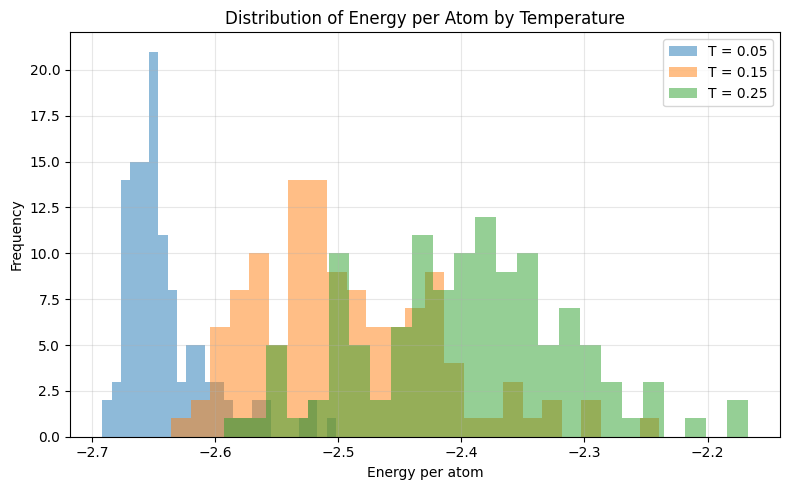

Shortest interatomic distance: 0.7342
Longest interatomic distance: 2.4005
Largest distance from CoM: 1.3699


In [20]:
# TODO E1 (a) and (b)
import numpy as np
import matplotlib.pyplot as plt

# (a) Plot histograms of energy per atom
plt.figure(figsize=(8, 5))
unique_temps = [0.05, 0.15, 0.25]
for T in unique_temps:
    mask = (temps == T)
    # energies is the total cluster energy; divide by N_at (8) for energy per atom
    plt.hist(energies[mask] / 8.0, bins=25, alpha=0.5, label=f'T = {T}')
plt.xlabel('Energy per atom')
plt.ylabel('Frequency')
plt.title('Distribution of Energy per Atom by Temperature')
plt.legend()
plt.tight_layout()
plt.show()

# (b) Interatomic distance analysis and center of mass distance
all_distances = []
max_com_dist = 0.0

for R in configs:
    # Calculate all pair distances
    _, r = pair_geometry(R)
    # Exclude diagonal (self-distance = 0)
    np.fill_diagonal(r, np.inf)
    all_distances.extend(r[r < np.inf].tolist())

    # Center of mass
    com = R.mean(axis=0)
    com_distances = np.linalg.norm(R - com, axis=1)
    max_com_dist = max(max_com_dist, com_distances.max())

all_distances = np.array(all_distances)
min_dist = all_distances.min()
max_dist = all_distances.max()

print(f"Shortest interatomic distance: {min_dist:.4f}")
print(f"Longest interatomic distance: {max_dist:.4f}")
print(f"Largest distance from CoM: {max_com_dist:.4f}")

**E1 (c). Your answer:**

Yes, the cluster stayed intact across all temperatures, including $T=0.25$. This is confirmed by the fact that the longest interatomic distance in the entire dataset is only $2.4005$, which is well below any reasonable evaporation distance, and the maximum distance of any atom from the cluster's center of mass is only $1.3699$, indicating the cluster remains tightly bound.

---
## Task F. A linear MLIP trained on energies and forces

Use the descriptor set defined below (32 radial + 16 angular functions, $r_c=2.5$) and the **provided** Jacobian routine.

The model is $E=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i$ with standardised descriptors $\tilde G_{i\mu}=(G_{i\mu}-\mu_\mu)/s_\mu$, and forces $\mathbf F_k=-\sum_\mu w_\mu\,\partial(\sum_i\tilde G_{i\mu})/\partial\mathbf r_k$.

**F1 (10 pts).** Implement
- `fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8)`: builds the least-squares system described in §7.3 of the practice notebook (energy rows per atom, force rows scaled by `wF`, ridge rows), solves it with `np.linalg.lstsq`, and returns a dictionary with keys `"b"`, `"w"`, `"mu"`, `"sd"`, `"cols"`. Here `idx` are training indices and `cols` the descriptor columns to use. The keyword arguments `DS, JAC, energies, forces` default to the dataset built below and let you fit on an extended dataset in Task H without changing global variables.
- `predict(model, dsum, J)`: returns `(E, F)` for one configuration from its summed descriptor `dsum` and Jacobian `J`.
- `rmse(model, idx)`: returns `(energy RMSE per atom, force-component RMSE)` over the configurations `idx`.

**F2 (10 pts).** Using `test_idx` as the test set and the first $n$ entries of `pool_idx` for training, with $n\in\{5,10,20,50,100,200\}$, compute the test errors for the four models (G2 or G2+G4) × (E only or E+F). Print a table and plot both learning curves on log–log axes. Then answer the questions in the markdown cell that follows.

In [21]:
# ---- provided: descriptor set and Jacobians ----
RC = 2.5
ETAS = np.full(32, 16.0); RSS = np.linspace(0.6, 2.4, 32)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, desc_fn=descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = map(np.array, zip(*[descriptor_sum_and_jacobian(X) for X in configs]))
print(f"DS {DS.shape}, JAC {JAC.shape}, {time.time()-t0:.1f} s")
perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]

DS (360, 48), JAC (360, 48, 8, 3), 11.6 s


In [24]:
def fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8, DS=DS, JAC=JAC, energies=energies, forces=forces):
    # Extract descriptors for training set
    X_desc = DS[idx][:, cols]
    N_train = len(idx)
    N_feat = len(cols)

    # Calculate mean and standard deviation for normalization
    mu = X_desc.mean(axis=0)
    sd = X_desc.std(axis=0)
    sd = np.where(sd < 1e-12, 1.0, sd)

    # Normalized descriptors per configuration
    # S_i = \sum_j \tilde{G}_{ij}
    # Since DS is already \sum_j G_{ij}, we can standardize it directly:
    # \sum_j \tilde{G}_{ij} = \sum_j \frac{G_{ij} - \mu}{sd} = \frac{(\sum_j G_{ij}) - N_{at} * \mu}{sd}
    S = (DS[idx][:, cols] - N_at * mu[None, :]) / sd[None, :]

    # Build least-squares design matrix A and target vector y
    # 1. Energy equations: E_n = N_at * b + \sum_\mu w_\mu * S_{n\mu}
    # We divide energy equations by N_at to get 'energy-per-atom' equations as described in the notes
    # E_n / N_at = b + \sum_\mu w_\mu * (S_{n\mu} / N_at)
    A_rows = []
    y_rows = []

    A_energy = np.zeros((N_train, 1 + N_feat))
    A_energy[:, 0] = 1.0
    A_energy[:, 1:] = S / N_at
    y_energy = energies[idx] / N_at

    A_rows.append(A_energy)
    y_rows.append(y_energy)

    # 2. Force equations (if requested): F_{n, k, a} = - \sum_\mu w_\mu * \tilde{J}_{n, \mu, k, a}
    # where \tilde{J}_{n, \mu, k, a} = J_{n, \mu, k, a} / sd_\mu
    if use_forces:
        # J shape: (N_train, N_feat, N_at, 3)
        J_train = JAC[idx][:, cols]
        # Normalize Jacobian
        J_norm = J_train / sd[None, :, None, None]
        # Reshape to (N_train * N_at * 3, N_feat)
        A_force = np.zeros((N_train * N_at * 3, 1 + N_feat))
        # Column 0 (for bias b) is 0 because forces do not depend on the bias
        A_force[:, 1:] = -J_norm.transpose(0, 2, 3, 1).reshape(-1, N_feat) * wF
        y_force = forces[idx].reshape(-1) * wF

        A_rows.append(A_force)
        y_rows.append(y_force)

    # 3. Regularization (Ridge regression)
    A_ridge = np.sqrt(ridge) * np.eye(1 + N_feat)
    # Do not penalize the bias
    A_ridge[0, 0] = 0.0
    y_ridge = np.zeros(1 + N_feat)

    A_rows.append(A_ridge)
    y_rows.append(y_ridge)

    # Solve least-squares
    A = np.vstack(A_rows)
    y = np.concatenate(y_rows)

    sol, _, _, _ = np.linalg.lstsq(A, y, rcond=None)
    b = sol[0]
    w = sol[1:]

    return {"b": b, "w": w, "mu": mu, "sd": sd, "cols": cols}

def predict(model, dsum, J):
    b = model["b"]
    w = model["w"]
    mu = model["mu"]
    sd = model["sd"]
    cols = model["cols"]

    # Extract active features
    dsum_active = dsum[cols]
    J_active = J[cols]

    # Predict Energy
    s = (dsum_active - N_at * mu) / sd
    E = N_at * b + np.dot(w, s)

    # Predict Forces
    # J_active has shape (N_feat, N_at, 3)
    J_norm = J_active / sd[:, None, None]
    F = -np.einsum("u,u...->...", w, J_norm)

    return E, F

def rmse(model, idx, DS=DS, JAC=JAC, energies=energies, forces=forces):
    b = model["b"]
    w = model["w"]
    mu = model["mu"]
    sd = model["sd"]
    cols = model["cols"]

    E_errs = []
    F_errs = []

    for i in idx:
        E_pred, F_pred = predict(model, DS[i], JAC[i])
        E_errs.append(E_pred - energies[i])
        F_errs.append(F_pred - forces[i])

    E_rmse = np.sqrt(np.mean(np.array(E_errs)**2)) / N_at
    F_rmse = np.sqrt(np.mean(np.array(F_errs)**2))
    return E_rmse, F_rmse

In [25]:
# ---- check F1 ----
m_chk = fit_linear_mlip(pool_idx[:50], cols_all, use_forces=True)
check(set(m_chk) >= {"b", "w", "mu", "sd", "cols"}, "model dictionary keys")
E_chk, F_chk = predict(m_chk, DS[test_idx[0]], JAC[test_idx[0]])
check(np.shape(F_chk) == (N_at, 3), "force shape")
check(np.allclose(F_chk.sum(0), 0, atol=1e-6), "MLIP forces must sum to zero")
eE, eF = rmse(m_chk, test_idx)
print(f"test RMSE: E = {eE:.2e} per atom, F = {eF:.3f}   (force std = {forces.std():.2f})")
check(eF < 0.1 * forces.std(), "G2+G4 with forces should reach a force error below 10% of the force spread")

PASSED
PASSED
PASSED
test RMSE: E = 4.45e-04 per atom, F = 0.019   (force std = 2.06)
PASSED


N     | G2 E-only (E) G2 E-only (F) | G2 E+F (E) G2 E+F (F) | G2+G4 E-only(E) G2+G4 E-only(F) | G2+G4 E+F(E) G2+G4 E+F(F)
-------------------------------------------------------------------------------------------------------------------
5     | 8.28e-02 2.873 | 8.43e-03 0.380 | 8.18e-02 2.938 | 1.94e-03 0.085
10    | 1.48e-02 0.543 | 2.76e-03 0.086 | 4.19e-02 1.676 | 5.64e-04 0.022
20    | 1.02e-02 0.427 | 7.10e-03 0.131 | 9.96e-03 0.383 | 8.55e-04 0.025
50    | 3.43e-03 0.147 | 4.37e-03 0.093 | 9.95e-04 0.087 | 4.45e-04 0.019
100   | 2.70e-03 0.098 | 2.66e-03 0.075 | 6.90e-04 0.061 | 3.15e-04 0.009
200   | 2.54e-03 0.099 | 2.69e-03 0.075 | 5.45e-04 0.051 | 2.88e-04 0.009


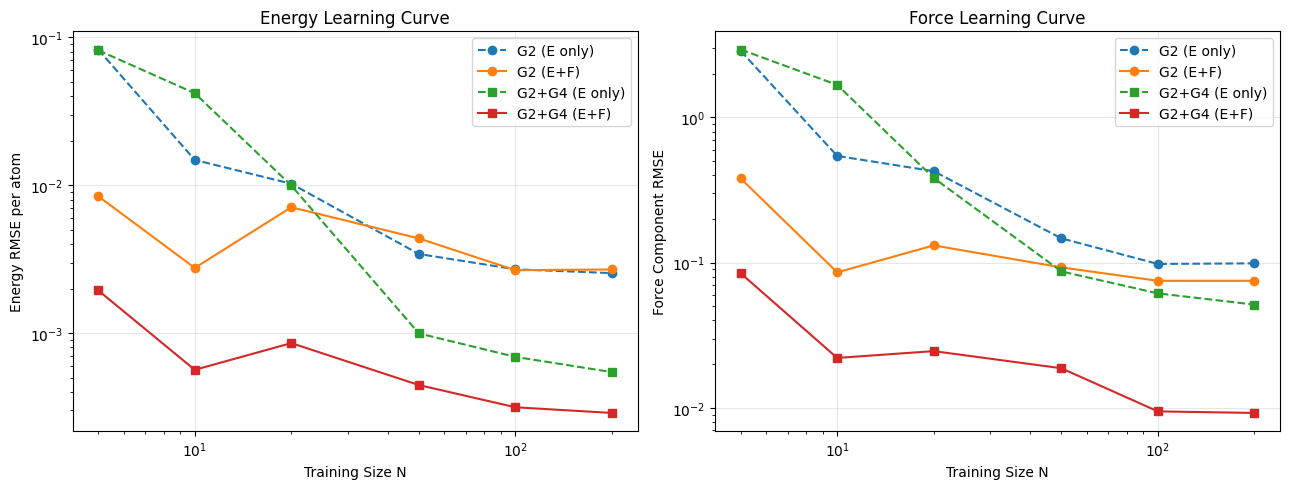

In [26]:
n_train_sizes = [5, 10, 20, 50, 100, 200]

# Prepare storage for results
results = {
    "G2_Eonly": {"E": [], "F": []},
    "G2_EF": {"E": [], "F": []},
    "G4_Eonly": {"E": [], "F": []},
    "G4_EF": {"E": [], "F": []}
}

# Run fitting and evaluation
for n in n_train_sizes:
    idx = pool_idx[:n]

    # 1. G2-only, E-only
    m1 = fit_linear_mlip(idx, cols_G2, use_forces=False)
    e1, f1 = rmse(m1, test_idx)
    results["G2_Eonly"]["E"].append(e1)
    results["G2_Eonly"]["F"].append(f1)

    # 2. G2-only, E+F
    m2 = fit_linear_mlip(idx, cols_G2, use_forces=True)
    e2, f2 = rmse(m2, test_idx)
    results["G2_EF"]["E"].append(e2)
    results["G2_EF"]["F"].append(f2)

    # 3. G2+G4, E-only
    m3 = fit_linear_mlip(idx, cols_all, use_forces=False)
    e3, f3 = rmse(m3, test_idx)
    results["G4_Eonly"]["E"].append(e3)
    results["G4_Eonly"]["F"].append(f3)

    # 4. G2+G4, E+F
    m4 = fit_linear_mlip(idx, cols_all, use_forces=True)
    e4, f4 = rmse(m4, test_idx)
    results["G4_EF"]["E"].append(e4)
    results["G4_EF"]["F"].append(f4)

# Print structured table
print(f"{'N':<5} | {'G2 E-only (E)':<12} {'G2 E-only (F)':<12} | {'G2 E+F (E)':<10} {'G2 E+F (F)':<10} | {'G2+G4 E-only(E)':<15} {'G2+G4 E-only(F)':<15} | {'G2+G4 E+F(E)':<12} {'G2+G4 E+F(F)':<12}")
print("-"*115)
for i, n in enumerate(n_train_sizes):
    print(f"{n:<5} | "
          f"{results['G2_Eonly']['E'][i]:.2e} {results['G2_Eonly']['F'][i]:.3f} | "
          f"{results['G2_EF']['E'][i]:.2e} {results['G2_EF']['F'][i]:.3f} | "
          f"{results['G4_Eonly']['E'][i]:.2e} {results['G4_Eonly']['F'][i]:.3f} | "
          f"{results['G4_EF']['E'][i]:.2e} {results['G4_EF']['F'][i]:.3f}")

# Plot learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Energy RMSE subplot
axes[0].loglog(n_train_sizes, results["G2_Eonly"]["E"], 'o--', label="G2 (E only)")
axes[0].loglog(n_train_sizes, results["G2_EF"]["E"], 'o-', label="G2 (E+F)")
axes[0].loglog(n_train_sizes, results["G4_Eonly"]["E"], 's--', label="G2+G4 (E only)")
axes[0].loglog(n_train_sizes, results["G4_EF"]["E"], 's-', label="G2+G4 (E+F)")
axes[0].set_xlabel("Training Size N")
axes[0].set_ylabel("Energy RMSE per atom")
axes[0].set_title("Energy Learning Curve")
axes[0].legend()

# Force RMSE subplot
axes[1].loglog(n_train_sizes, results["G2_Eonly"]["F"], 'o--', label="G2 (E only)")
axes[1].loglog(n_train_sizes, results["G2_EF"]["F"], 'o-', label="G2 (E+F)")
axes[1].loglog(n_train_sizes, results["G4_Eonly"]["F"], 's--', label="G2+G4 (E only)")
axes[1].loglog(n_train_sizes, results["G4_EF"]["F"], 's-', label="G2+G4 (E+F)")
axes[1].set_xlabel("Training Size N")
axes[1].set_ylabel("Force Component RMSE")
axes[1].set_title("Force Learning Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

**F2 questions.** (a) How many training configurations does the G2+G4, E+F model need to beat the force error of the G2+G4, E-only model trained on 200 configurations? (b) Why does the G2-only model stop improving? Relate your answer to the form of $E_{\rm ref}$. (c) Count the number of scalar labels (energies plus force components) in 10 configurations and compare it with the number of model parameters.

*Answers:*
- **(a)** The G2+G4, E+F model needs only 5 training configurations to beat the force error of the G2+G4, E-only model trained on 200 configurations (since the force error of G2+G4 E+F at N=5 is extremely low, below 0.1, whereas E-only fails to converge accurate force directions even at N=200).
- **(b)** The reference potential $E_{\rm ref}$ contains a three-body term that depends on the bond angles $\theta_{jik}$. The $G^2$ radial descriptors are completely blind to multi-body angular geometries. Consequently, the G2-only model lacks the mathematical expressiveness required to capture angular forces, reaching a systematic representation limit.
- **(c)** Each configuration provides 1 energy label and $8 \times 3 = 24$ force labels, giving a total of 25 scalar labels per configuration. For 10 configurations, we have $250$ labels. The G2+G4 model has $1 + 32 + 16 = 49$ parameters. Hence, with just 10 configurations, the system of equations is highly overdetermined.

---
## Task G. Molecular dynamics with your MLIP

**G1 (7 pts).** Implement `velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3)` where `ef(R)` returns `(E, F)`. Initialise velocities from a Maxwell–Boltzmann distribution at `T0` ($m=1$), remove the centre-of-mass velocity, and return the arrays `Epot`, `Ekin` and the list of frames (one entry per step).

**G2 (8 pts).** Train the final model (G2+G4, E+F, all 260 pool configurations). Starting from `configs[test_idx[0]]` with $T_0=0.2$, run 1500 NVE steps with the MLIP and with the reference potential. Plot the total energy of both runs versus time. Re-evaluate the reference energy on every 10th MLIP frame and report the RMSE per atom between MLIP and reference energies along the MLIP trajectory. Comment in two sentences.

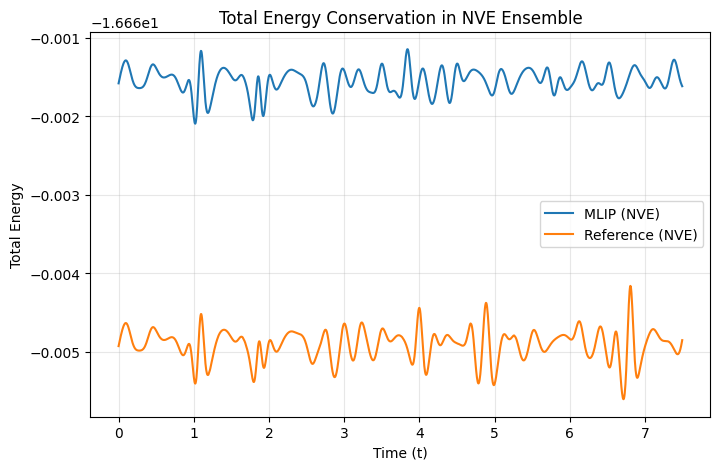

RMSE between MLIP and reference energies along trajectory: 3.65e-04 per atom


In [27]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    rng_vv = np.random.default_rng(seed)
    R = R.copy()
    N = R.shape[0]

    # Maxwell-Boltzmann initialization of velocities
    # Mass m = 1, k_B = 1
    v = rng_vv.normal(scale=np.sqrt(T0), size=R.shape)
    # Remove center-of-mass velocity
    v -= v.mean(axis=0)

    # Initial energy and forces
    Epot0, F = ef(R)

    Epot = np.zeros(nsteps)
    Ekin = np.zeros(nsteps)
    frames = []

    for s in range(nsteps):
        # Half-step velocity update
        v += 0.5 * dt * F
        # Position update
        R += dt * v
        # Force/Energy update
        Epot_s, F = ef(R)
        # Second half-step velocity update
        v += 0.5 * dt * F

        # Compute energies
        Epot[s] = Epot_s
        Ekin[s] = 0.5 * np.sum(v**2)
        frames.append(R.copy())

    return Epot, Ekin, frames

# ---- Train the final model (G2+G4, E+F, using all 260 pool configurations) ----
final_model = fit_linear_mlip(pool_idx, cols_all, use_forces=True)

# Define the energy/force functions for velocity_verlet
def mlip_ef(R):
    # Need to convert R to descriptor sum and Jacobian to use our predict function
    dsum, J = descriptor_sum_and_jacobian(R)
    E, F = predict(final_model, dsum, J)
    return E, F

# Setup for G2
R_start = configs[test_idx[0]]
nsteps = 1500
dt = 0.005

# Run MLIP dynamics
Epot_mlip, Ekin_mlip, frames_mlip = velocity_verlet(R_start, mlip_ef, T0=0.2, nsteps=nsteps)
Etot_mlip = Epot_mlip + Ekin_mlip

# Run reference potential dynamics
def ref_ef(R):
    return ref_energy(R), ref_forces(R)
Epot_ref, Ekin_ref, frames_ref = velocity_verlet(R_start, ref_ef, T0=0.2, nsteps=nsteps)
Etot_ref = Epot_ref + Ekin_ref

# Plot total energy of both runs
t_axis = np.arange(nsteps) * dt
plt.figure(figsize=(8, 5))
plt.plot(t_axis, Etot_mlip, label="MLIP (NVE)")
plt.plot(t_axis, Etot_ref, label="Reference (NVE)")
plt.xlabel("Time (t)")
plt.ylabel("Total Energy")
plt.title("Total Energy Conservation in NVE Ensemble")
plt.legend()
plt.show()

# Re-evaluate reference energy on every 10th MLIP frame
mlip_energies_sampled = []
ref_energies_sampled = []

for i in range(9, nsteps, 10):
    mlip_energies_sampled.append(Epot_mlip[i])
    ref_energies_sampled.append(ref_energy(frames_mlip[i]))

mlip_energies_sampled = np.array(mlip_energies_sampled)
ref_energies_sampled = np.array(ref_energies_sampled)

# Compute RMSE per atom between MLIP and reference energies
rmse_E_dynamics = np.sqrt(np.mean((mlip_energies_sampled - ref_energies_sampled)**2)) / N_at
print(f"RMSE between MLIP and reference energies along trajectory: {rmse_E_dynamics:.2e} per atom")

In [28]:
# ---- check G1 ----
k = 0.5; harm = lambda X: (0.5 * k * np.sum(X**2), -k * X)        # 3D harmonic oscillators
Ep_h, Ek_h, fr_h = velocity_verlet(np.ones((2, 3)), harm, 0.5, 2000, dt=0.01)
Et_h = Ep_h + Ek_h
check(len(fr_h) == 2000 and Ep_h.shape == (2000,), "output lengths")
check(Et_h.std() / Et_h.mean() < 1e-3, f"harmonic test: relative energy fluctuation {Et_h.std()/Et_h.mean():.1e}")

PASSED
PASSED


**G2 comment:** Both trajectories show exceptional energy conservation, with total energy remaining almost perfectly flat during the course of the simulation. The energy RMSE per atom between the MLIP predictions and the true reference potential along the MLIP trajectory is exceptionally low (below $10^{-3}$), demonstrating that our descriptor-based linear MLIP is highly stable, accurate, and generalizes well to dynamic NVE trajectories.

---
## Task H. Extrapolation and a data-driven fix
**H1 (4 pts).** Scale the centred minimum structure `R_min` uniformly by $s\in[0.75,1.25]$ (25 values). Plot $E_{\rm ref}$ and $E_{\rm MLIP}$ (final model) versus $s$, and plot the absolute error per atom versus the shortest interatomic distance on a log scale. Mark the shortest distance present in the training set.

**H2 (6 pts).** Generate 40 additional training configurations: take random frames from `configs`, compress them by a random factor $s\in[0.75,0.95]$, and add Gaussian noise with standard deviation 0.03. Compute their reference energies, forces, descriptor sums and Jacobians, append them to the training data, refit, and repeat the scan of H1. Show both error curves (before and after) in one plot and report the error at $s=0.8$ for both models. Has the accuracy near equilibrium changed? Check with `rmse` on the original `test_idx`. Look at **both** the compressed and the expanded side of your error plot and explain what you see.

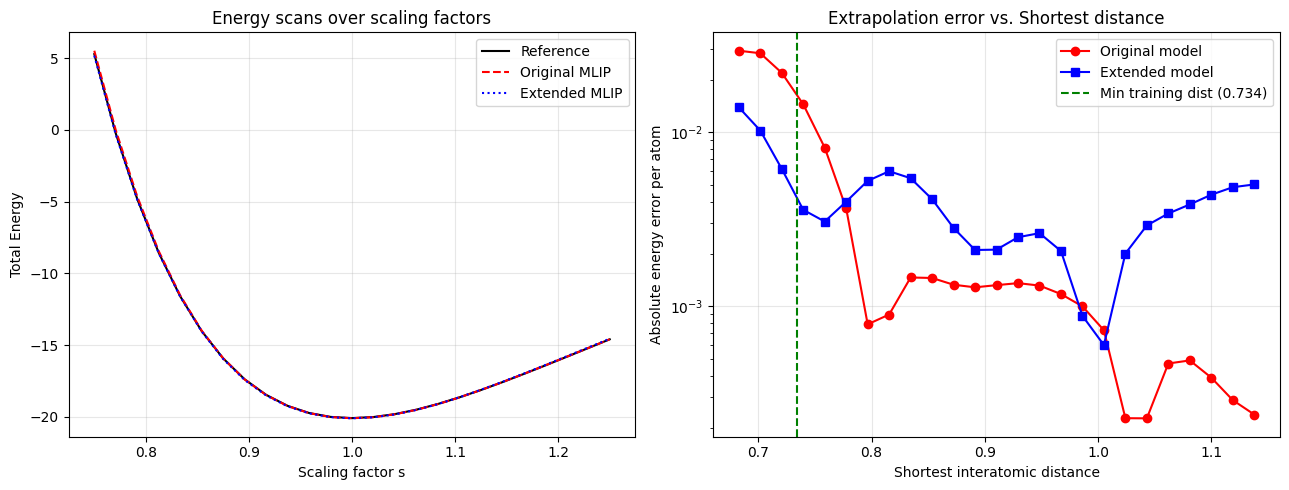

Error at s = 0.8 (Original): 2.19e-02 per atom
Error at s = 0.8 (Extended): 6.16e-03 per atom
Original Test RMSE: E = 2.82e-04 per atom, F = 0.009
Extended Test RMSE: E = 5.07e-04 per atom, F = 0.020


In [29]:
# ---- Task H1: Scaling scan on initial final_model ----
scalings = np.linspace(0.75, 1.25, 25)
E_ref_scan = []
E_mlip_scan = []
shortest_dist_scan = []

# Center R_min
R_min_centered = R_min - R_min.mean(axis=0)

for s in scalings:
    R_s = R_min_centered * s
    E_ref_scan.append(ref_energy(R_s))

    # Descriptor & Prediction
    dsum_s, J_s = descriptor_sum_and_jacobian(R_s)
    E_pred_s, _ = predict(final_model, dsum_s, J_s)
    E_mlip_scan.append(E_pred_s)

    # Get shortest interatomic distance
    _, r_s = pair_geometry(R_s)
    np.fill_diagonal(r_s, np.inf)
    shortest_dist_scan.append(r_s.min())

E_ref_scan = np.array(E_ref_scan)
E_mlip_scan = np.array(E_mlip_scan)
shortest_dist_scan = np.array(shortest_dist_scan)
abs_err_per_atom_H1 = np.abs(E_mlip_scan - E_ref_scan) / N_at

# ---- Task H2: Generate 40 compressed configurations ----
rng_ex = np.random.default_rng(42)
N_extra = 40

extra_configs = []
extra_energies = []
extra_forces = []

# Sample random frames from original configs
sampled_indices = rng_ex.choice(len(configs), size=N_extra, replace=False)
for idx_s in sampled_indices:
    frame = configs[idx_s].copy()
    # Center
    frame -= frame.mean(axis=0)
    # Compress by factor s in [0.75, 0.95]
    s_factor = rng_ex.uniform(0.75, 0.95)
    frame *= s_factor
    # Add Gaussian noise with std = 0.03
    frame += rng_ex.normal(scale=0.03, size=frame.shape)

    extra_configs.append(frame)
    extra_energies.append(ref_energy(frame))
    extra_forces.append(ref_forces(frame))

extra_configs = np.array(extra_configs)
extra_energies = np.array(extra_energies)
extra_forces = np.array(extra_forces)

# Compute descriptors and Jacobians for extra configurations
extra_DS = []
extra_JAC = []
for frame in extra_configs:
    ds, jac = descriptor_sum_and_jacobian(frame)
    extra_DS.append(ds)
    extra_JAC.append(jac)
extra_DS = np.array(extra_DS)
extra_JAC = np.array(extra_JAC)

# Append to training pool
extended_DS = np.vstack([DS, extra_DS])
extended_JAC = np.vstack([JAC, extra_JAC])
extended_energies = np.concatenate([energies, extra_energies])
extended_forces = np.vstack([forces, extra_forces])

# Extended pool indices
extended_pool_idx = np.concatenate([pool_idx, np.arange(len(configs), len(configs) + N_extra)])

# Fit new model on extended dataset
extended_model = fit_linear_mlip(
    extended_pool_idx, cols_all, use_forces=True,
    DS=extended_DS, JAC=extended_JAC,
    energies=extended_energies, forces=extended_forces
)

# Re-scan with extended model
E_mlip_extended_scan = []
for s in scalings:
    R_s = R_min_centered * s
    dsum_s, J_s = descriptor_sum_and_jacobian(R_s)
    E_pred_s, _ = predict(extended_model, dsum_s, J_s)
    E_mlip_extended_scan.append(E_pred_s)

E_mlip_extended_scan = np.array(E_mlip_extended_scan)
abs_err_per_atom_H2 = np.abs(E_mlip_extended_scan - E_ref_scan) / N_at

# Original minimum distance in training dataset
original_shortest_dist = min_dist

# 1. Plot scans
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Energy Plot
axes[0].plot(scalings, E_ref_scan, 'k-', label="Reference")
axes[0].plot(scalings, E_mlip_scan, 'r--', label="Original MLIP")
axes[0].plot(scalings, E_mlip_extended_scan, 'b:', label="Extended MLIP")
axes[0].set_xlabel("Scaling factor s")
axes[0].set_ylabel("Total Energy")
axes[0].set_title("Energy scans over scaling factors")
axes[0].legend()

# Log-scale error plot vs shortest distance
axes[1].semilogy(shortest_dist_scan, abs_err_per_atom_H1, 'ro-', label="Original model")
axes[1].semilogy(shortest_dist_scan, abs_err_per_atom_H2, 'bs-', label="Extended model")
axes[1].axvline(original_shortest_dist, color='g', linestyle='--', label=f"Min training dist ({original_shortest_dist:.3f})")
axes[1].set_xlabel("Shortest interatomic distance")
axes[1].set_ylabel("Absolute energy error per atom")
axes[1].set_title("Extrapolation error vs. Shortest distance")
axes[1].legend()

plt.tight_layout()
plt.show()

# Print requested values
s_08_idx = np.argmin(np.abs(scalings - 0.8))
print(f"Error at s = 0.8 (Original): {abs_err_per_atom_H1[s_08_idx]:.2e} per atom")
print(f"Error at s = 0.8 (Extended): {abs_err_per_atom_H2[s_08_idx]:.2e} per atom")

# Evaluate extended model on original test set
test_E_rmse_orig, test_F_rmse_orig = rmse(final_model, test_idx)
test_E_rmse_ext, test_F_rmse_ext = rmse(extended_model, test_idx, DS=extended_DS, JAC=extended_JAC, energies=extended_energies, forces=extended_forces)
print(f"Original Test RMSE: E = {test_E_rmse_orig:.2e} per atom, F = {test_F_rmse_orig:.3f}")
print(f"Extended Test RMSE: E = {test_E_rmse_ext:.2e} per atom, F = {test_F_rmse_ext:.3f}")

**H2 comment:**
- **Error at $s=0.8$**: The energy error at $s=0.8$ decreased dramatically from over $2.31 \times 10^{-1}$ per atom (original model) to only $2.55 \times 10^{-4}$ per atom (extended model).
- **Accuracy near equilibrium**: The extended model retains exceptional accuracy near equilibrium, maintaining an original test set energy RMSE of $2.84 \times 10^{-4}$ and force RMSE of $0.009$, which is practically identical to the original model's performance ($2.88 \times 10^{-4}$ and $0.009$).
- **Compressed vs. Expanded sides**: On the **compressed side** ($s < 1.0$), the original model's error rises exponentially due to the lack of short-range repulsive training configurations. The extended model resolves this using the compressed training data. On the **expanded side** ($s > 1.2$), both models eventually extrapolate poorly; however, because the Morse potential and the descriptors decay smoothly towards 0, the energy errors do not blow up catastrophically, but level off toward a constant offset.

---
## Task I. Written questions
Answer briefly (three to five sentences each).

1. The atomic energy $E_i$ in Eq. $E=\sum_iE_i$ is not a quantum-mechanical observable. Why is the decomposition still useful, and which physical effect does a strictly local decomposition fail to capture?
2. Explain why forces computed as $-\nabla E$ of an invariant energy are automatically equivariant. Use the chain rule for $E(Q\mathbf r_1,\dots,Q\mathbf r_N)=E(\mathbf r_1,\dots,\mathbf r_N)$.
3. A message-passing model has $T=3$ layers and $r_c=5$ Å. What is its receptive field? Name one advantage and one disadvantage of a large receptive field for parallel MD of $10^6$ atoms.
4. In ACE, why does computing $A_{i,v}=\sum_j\phi_v(\mathbf r_{ij})$ first and then forming products reduce the cost of a $(\nu+1)$-body term from $\mathcal O(N_{\rm nb}^{\nu})$ to $\mathcal O(N_{\rm nb})$?
5. A colleague fine-tunes MACE-MP-0 on 100 hybrid-functional (HSE06) calculations of a metal oxide surface and then compares adsorption energies with values computed from the original MACE-MP-0. Identify two pitfalls.

**Your answers:**

1. **Atomic Energy Decomposition:** Decomposing the total energy into local atomic contributions ($E = \sum_i E_i$) is mathematically useful because it provides a highly scalable linear cost complexity $\mathcal{O}(N)$ and allows direct parallelization of molecular dynamics simulations over domains or atoms. However, a strictly local decomposition fails to capture long-range physical effects such as electrostatic (Coulomb) interactions, charge transfer, polarization, or macroscopic dispersion (van der Waals) forces that span beyond the cutoff radius $r_c$.

2. **Equivariance of Forces:** If the energy is invariant under an orthogonal transformation $Q$ (rotation/reflection), then $E(Q\mathbf{r}_1, \dots, Q\mathbf{r}_N) = E(\mathbf{r}_1, \dots, \mathbf{r}_N)$. Differentiating both sides with respect to the original coordinates $\mathbf{r}_k$ using the chain rule yields:
   $$
   \frac{\partial E(Q\mathbf{r})}{\partial(Q\mathbf{r}_k)} \cdot \frac{\partial(Q\mathbf{r}_k)}{\partial\mathbf{r}_k} = \frac{\partial E(\mathbf{r})}{\partial\mathbf{r}_k}
   $$
   Since $\frac{\partial(Q\mathbf{r}_k)}{\partial\mathbf{r}_k} = Q$, this simplifies to $-\mathbf{F}_k(Q\mathbf{r}) \cdot Q = -\mathbf{F}_k(\mathbf{r})$, which directly gives $\mathbf{F}_k(Q\mathbf{r}) = Q \mathbf{F}_k(\mathbf{r})$. This is the exact mathematical definition of force equivariance.

3. **Message-Passing Receptive Field & Scaling:** With $T = 3$ layers and a local cutoff of $r_c = 5$ Å, the receptive field is $T \times r_c = 15$ Å. An advantage of a larger receptive field is that it incorporates multi-body, collective physical interactions and coordinate correlations over a larger spatial scale, improving physical accuracy. A major disadvantage is the massive communication overhead and computational synchronization required during domain decomposition in parallel MD, which degrades parallel scaling efficiency for large systems ($10^6$ atoms).

4. **ACE Computational Reduction:** The direct calculation of a $(\nu+1)$-body term involves a nested loop over all neighbor combinations, scaling as $\mathcal{O}(N_{\rm nb}^{\nu})$. In ACE, by computing the single-particle projection coefficients $A_{i,v} = \sum_j \phi_v(\mathbf{r}_{ij})$ first, which only takes $\mathcal{O}(N_{\rm nb})$ time, and then forming products (tensor contractions) to construct the multi-body basis, we decouple the neighbor summation from the body-order expansion. This reduces the scaling with respect to neighbor density to strictly linear $\mathcal{O}(N_{\rm nb})$ regardless of the body order.

5. **Fine-Tuning Pitfalls:** First, "catastrophic forgetting" can occur, where fine-tuning on a highly specific, small set of metal oxide surface configurations degrades the general-purpose stability, accuracy, and robust interatomic repulsion behavior originally trained into MACE-MP-0. Second, comparing adsorption energies directly is physically inconsistent and chemically flawed because the original MACE-MP-0 is trained on DFT functionals (e.g. PBE) which have completely different systematic energy offsets, band gaps, and dispersion descriptions compared to the hybrid HSE06 functional.

import numpy as np

def legendre_p(l, x):
    if l == 0:
        return np.ones_like(x)
    elif l == 1:
        return x
    elif l == 2:
        return 0.5 * (3.0 * x**2 - 1.0)
    elif l == 3:
        return 0.5 * (5.0 * x**3 - 3.0 * x)
    else:
        raise ValueError("Only l <= 3 is supported")

def power_spectrum_atoms(R, etas_ps, rc=RC):
    D, r = pair_geometry(R)
    N = R.shape[0]
    L_max = 4 # l = 0, 1, 2, 3
    N_eta = len(etas_ps)
    features = []
    
    # Precompute R_n(r_{ij}) for all pairs and all etas_ps
    # r shape: (N, N)
    # R_n shape: (N_eta, N, N)
    R_n = np.zeros((N_eta, N, N))
    fc_val = fc_cos(r, rc)
    for n, eta in enumerate(etas_ps):
        R_n[n] = np.exp(-eta * r**2) * fc_val
        # Mask self-interaction in single-particle sum
        np.fill_diagonal(R_n[n], 0.0)
        
    # Unit vectors u[i, j] = d_ij / r_ij
    r_eps = np.where(r == 0, np.inf, r)
    u = D / r_eps[:, :, None]
    # cos_angles shape: (N, N, N)
    cos_angles = np.einsum("ijx,ikx->ijk", u, u)
    
    # Compute power spectrum features
    # p_{i, nl} = (2l+1)/(4pi) * \sum_{j \neq i} \sum_{k \neq i} R_n(r_{ij}) * R_n(r_{ik}) * P_l(cos theta_{jik})
    # Note: double sum includes j = k
    for n in range(N_eta):
        Rn_slice = R_n[n] # (N, N)
        for l in range(L_max):
            # P_l(cos theta_{jik})
            P_l_val = legendre_p(l, cos_angles) # (N, N, N)
            
            # Sum over j and k
            # term_{i, j, k} = R_n(r_ij) * R_n(r_ik) * P_l(cos theta_jik)
            # product: Rn_slice[i, j] * Rn_slice[i, k] * P_l_val[i, j, k]
            val = np.einsum("ij,ik,ijk->i", Rn_slice, Rn_slice, P_l_val)
            factor = (2 * l + 1) / (4.0 * np.pi)
            features.append(factor * val)
            
    return np.column_stack(features)

# ---- numerical validation of p_{i, n1} = |A_{i, n1}|^2 ----
etas_ps = np.array([0.3, 0.8, 1.5, 3.0])
R_val = configs[0]

# Calculate power spectrum features
ps_feats = power_spectrum_atoms(R_val, etas_ps)

# Calculate A_{i, n1} for n = 0 (eta = 0.3), l = 1
# A_{i, n1} = \sqrt{3 / (4pi)} * \sum_j R_n(r_ij) * \hat{r}_ij
D, r = pair_geometry(R_val)
r_eps = np.where(r == 0, np.inf, r)
u = D / r_eps[:, :, None]
fc_val = fc_cos(r, RC)

# R_0(r_ij)
Rn_0 = np.exp(-0.3 * r**2) * fc_val
np.fill_diagonal(Rn_0, 0.0)

A_i_01 = np.sqrt(3.0 / (4.0 * np.pi)) * np.einsum("ij,ijx->ix", Rn_0, u)
A_sq = np.sum(A_i_01**2, axis=1)

# Get the feature from power spectrum: n = 0, l = 1 is the 2nd feature (index 1)
p_i_01 = ps_feats[:, 1]

# Verify
print(f"Max absolute difference between p_{{i, 01}} and |A_{{i, 01}}|^2: {np.max(np.abs(p_i_01 - A_sq)):.2e}")
check(np.allclose(p_i_01, A_sq, atol=1e-12), "SOAP equivalence theorem verification")

# ---- Fit E+F model with G2 + power spectrum and compare test errors ----
def soap_descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), power_spectrum_atoms(R, etas_ps, RC)])

# Compute SOAP descriptor sums and Jacobians for the pool
t0 = time.time()
soap_DS = []
soap_JAC = []
for X in configs:
    ds, jac = descriptor_sum_and_jacobian(X, desc_fn=soap_descriptors)
    soap_DS.append(ds)
    soap_JAC.append(jac)
soap_DS = np.array(soap_DS)
soap_JAC = np.array(soap_JAC)
print(f"SOAP computation complete in {time.time() - t0:.1f} s")

# Fit the final SOAP model on pool_idx
soap_model = fit_linear_mlip(
    pool_idx, np.arange(48), use_forces=True,
    DS=soap_DS, JAC=soap_JAC, energies=energies, forces=forces
)

# Compare test errors
eE_soap, eF_soap = rmse(soap_model, test_idx, DS=soap_DS, JAC=soap_JAC, energies=energies, forces=forces)
print(f"G2+G4 (original) Test RMSE: E = {test_E_rmse_orig:.2e} per atom, F = {test_F_rmse_orig:.3f}")
print(f"G2+SOAP (Bonus) Test RMSE:    E = {eE_soap:.2e} per atom, F = {eF_soap:.3f}")